<a href="https://colab.research.google.com/github/mn660875/NetSol-Challenges/blob/main/02_EDA_Worksheet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📝 EDA Worksheet — Auto-MPG Dataset
**Student Name:** ___________________________  |  **Date:** _______________

Complete every `# TODO` cell. Run the cells in order.  
Answer the written questions in the Markdown cells provided.

---
**Dataset:** Auto-MPG (UCI) | 398 rows × 9 columns


## Task 1 — Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

## Task 2 — Load & Inspect Data

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
col_names = ['mpg','cylinders','displacement','horsepower','weight',
             'acceleration','model_year','origin','car_name']

# Read dataset handling whitespace separators and setting ? as NaN
df = pd.read_csv(url, sep='\\s+', names=col_names, na_values='?')

print("Shape:", df.shape)
display(df.head())

Shape: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    object 
dtypes: float64(5), int64(3), object(1)
memory usage: 28.1+ KB


In [4]:
display(df.describe(include='all'))

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000,398.000000,398
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,305
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ford pinto
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050,1.572864,NaN
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627,0.802055,NaN
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,1.000000,NaN
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000,1.000000,NaN
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000,1.000000,NaN
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000,2.000000,NaN


**Q1.** How many rows and columns does the dataset have?  
**Answer:** 398 rows and 9 columns.

**Q2.** Which column contains missing values and how many?  
**Answer:** `horsepower` contains 6 missing values.

## Task 3 — Pre-Processing

In [5]:
print("Missing values per column:\n", df.isnull().sum())
df = df.dropna().reset_index(drop=True)
print("\nShape after dropping NaN values:", df.shape)

Missing values per column:
 mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64

Shape after dropping NaN values: (392, 9)


In [6]:
duplicates_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates_count}")
if duplicates_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Duplicates removed.")

Number of duplicate rows: 0


In [7]:
# 1. Convert columns to category type
df['cylinders'] = df['cylinders'].astype('category')
df['model_year'] = df['model_year'].astype('category')

# 2. Map origin from integers to labels
origin_map = {1: 'usa', 2: 'europe', 3: 'japan'}
df['origin'] = df['origin'].map(origin_map).astype('category')

# 3. Clean car_name column
df['car_name'] = df['car_name'].str.strip().str.lower()

display(df.head())

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,usa,ford torino


In [8]:
cat_cols = ['cylinders', 'origin', 'model_year']
num_cols = ['mpg', 'displacement', 'horsepower', 'weight', 'acceleration']

print("Categorical Columns:", cat_cols)
print("Numerical Columns:", num_cols)

Categorical Columns: ['cylinders', 'origin', 'model_year']
Numerical Columns: ['mpg', 'displacement', 'horsepower', 'weight', 'acceleration']


## Task 4 — Feature Engineering

In [9]:
df['mpg_level'] = pd.cut(df['mpg'], bins=[0, 17, 29, float('inf')], labels=['low', 'medium', 'high'], right=False)
display(df[['mpg', 'mpg_level']].head())

,mpg,mpg_level
0,18.0,medium
1,15.0,low
2,18.0,medium
3,16.0,low
4,17.0,medium


In [10]:
df['car_company'] = df['car_name'].apply(lambda x: x.split()[0])
print("Unique car companies represented:")
print(df['car_company'].unique())
display(df[['car_name', 'car_company']].head())

Unique car companies represented:
['chevrolet' 'buick' 'plymouth' 'amc' 'ford' 'pontiac' 'dodge' 'toyota'
 'datsun' 'volkswagen' 'peugeot' 'audi' 'saab' 'bmw' 'chevy' 'hi'
 'mercury' 'opel' 'fiat' 'oldsmobile' 'chrysler' 'mazda' 'volvo' 'renault'
 'toyouta' 'maxda' 'honda' 'subaru' 'chevroelt' 'capri' 'vw'
 'mercedes-benz' 'cadillac' 'mercedes' 'vokswagen' 'triumph' 'nissan']


,car_name,car_company
0,chevrolet chevelle malibu,chevrolet
1,buick skylark 320,buick
2,plymouth satellite,plymouth
3,amc rebel sst,amc
4,ford torino,ford


## Task 5 — Categorical EDA

/tmp/ipykernel_1069/3998888592.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='origin', ax=axes[0,0], palette='viridis')
/tmp/ipykernel_1069/3998888592.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='cylinders', ax=axes[0,1], palette='magma')
/tmp/ipykernel_1069/3998888592.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='mpg_level', ax=axes[1,0], palette='coolwarm')
/tmp/ipykernel_1069/3998888592.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be re

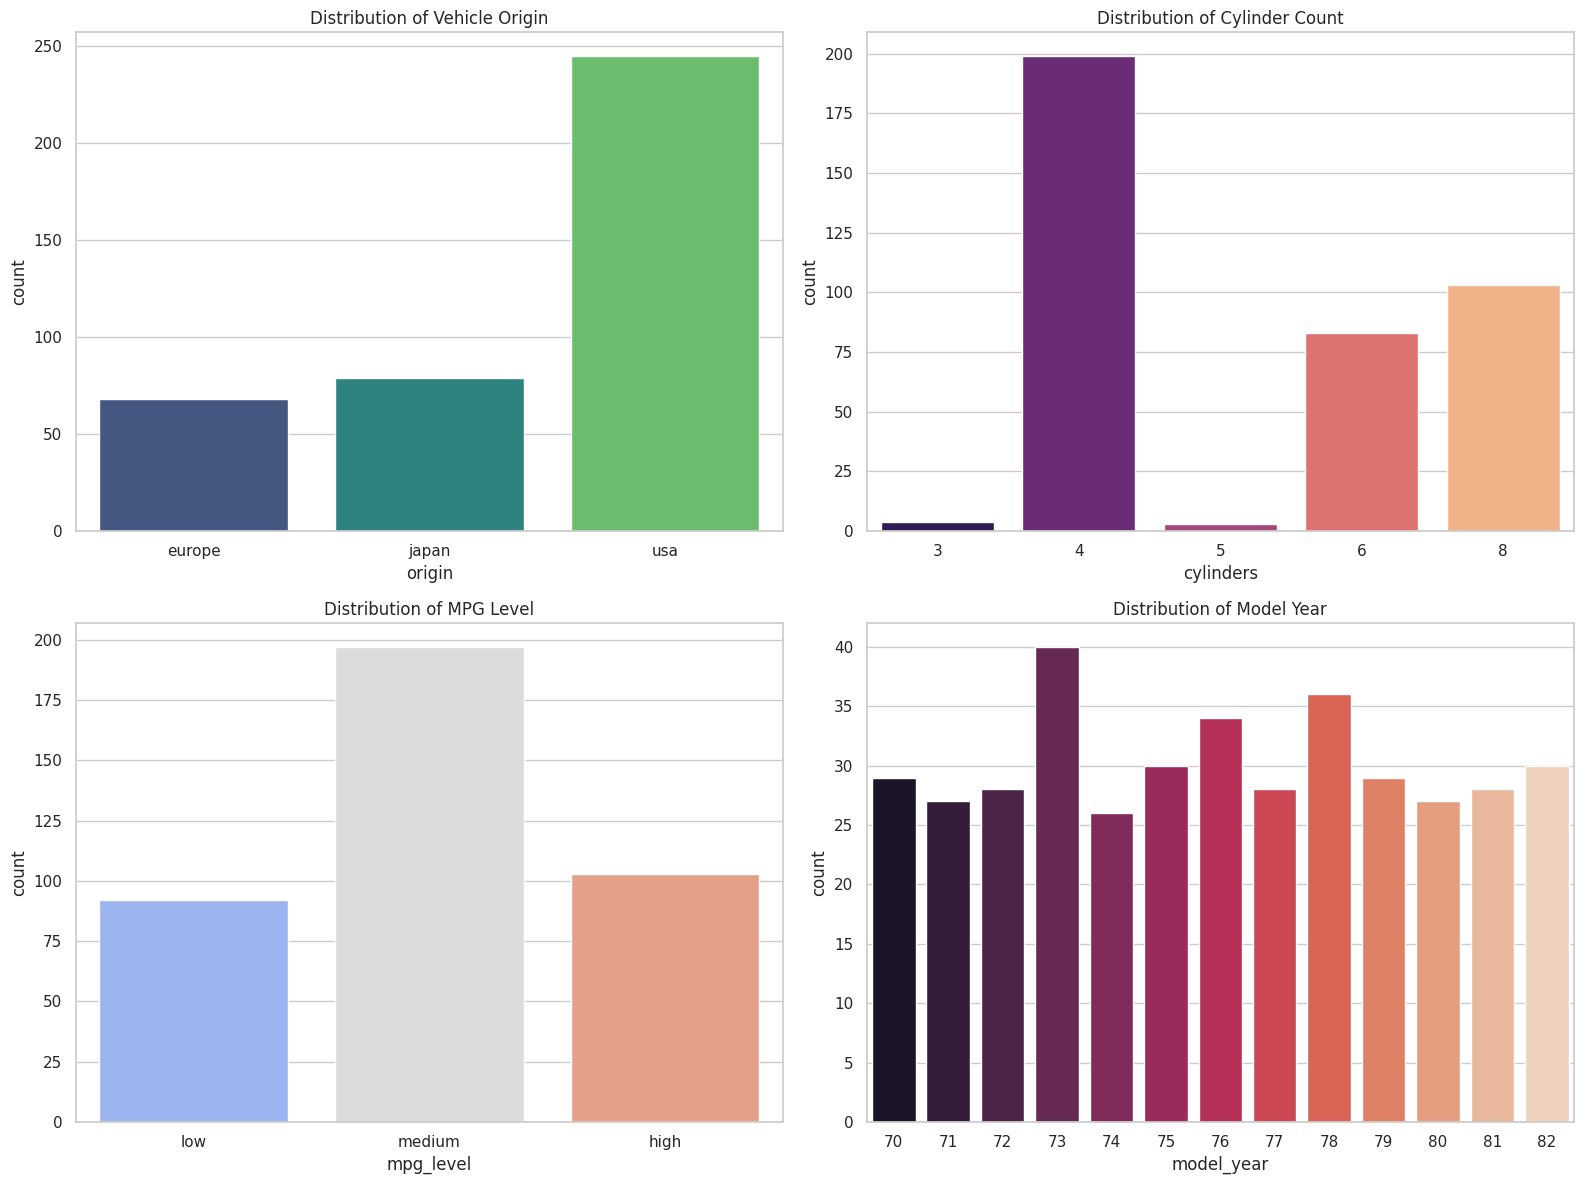

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

sns.countplot(data=df, x='origin', ax=axes[0,0], palette='viridis')
axes[0,0].set_title('Distribution of Vehicle Origin')

sns.countplot(data=df, x='cylinders', ax=axes[0,1], palette='magma')
axes[0,1].set_title('Distribution of Cylinder Count')

sns.countplot(data=df, x='mpg_level', ax=axes[1,0], palette='coolwarm')
axes[1,0].set_title('Distribution of MPG Level')

sns.countplot(data=df, x='model_year', ax=axes[1,1], palette='rocket')
axes[1,1].set_title('Distribution of Model Year')

plt.tight_layout()
plt.show()

In [12]:
for col in ['origin', 'cylinders', 'mpg_level']:
    counts = df[col].value_counts(normalize=True) * 100
    dominant_class = counts.index[0]
    dominant_percentage = counts.values[0]
    print(f"{col}: Dominant class is '{dominant_class}' with {dominant_percentage:.2f}%")

origin: Dominant class is 'usa' with 62.50%
cylinders: Dominant class is '4' with 50.77%
mpg_level: Dominant class is 'medium' with 50.26%


Crosstab:


origin,europe,japan,usa
cylinders,,,
3,0,4,0
4,61,69,69
5,3,0,0
6,4,6,73
8,0,0,103


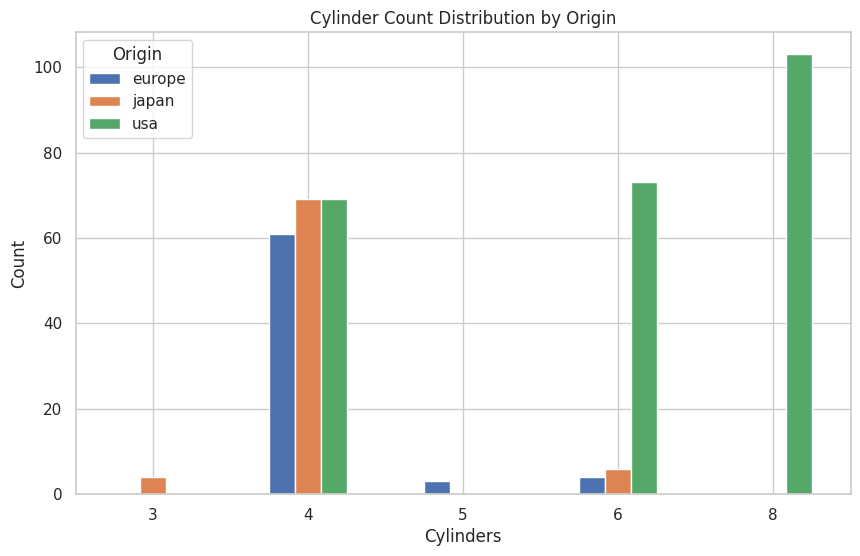

In [13]:
ct = pd.crosstab(df['cylinders'], df['origin'])
print("Crosstab:")
display(ct)

ct.plot(kind='bar', figsize=(10, 6))
plt.title('Cylinder Count Distribution by Origin')
plt.xlabel('Cylinders')
plt.ylabel('Count')
plt.legend(title='Origin')
plt.xticks(rotation=0)
plt.show()

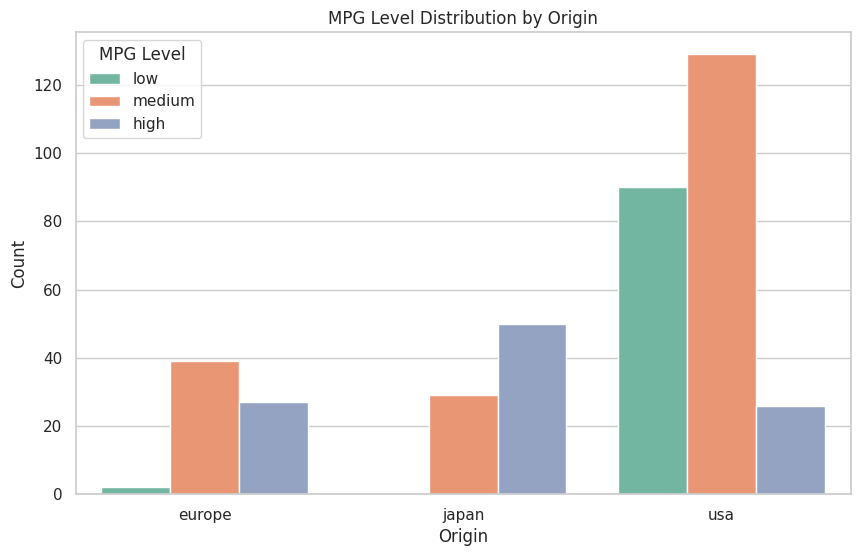

In [14]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='origin', hue='mpg_level', palette='Set2')
plt.title('MPG Level Distribution by Origin')
plt.xlabel('Origin')
plt.ylabel('Count')
plt.legend(title='MPG Level')
plt.show()

**Q3.** Which origin has **no** vehicles with low mpg_level?  
**Answer:** **japan** has no vehicles with low `mpg_level`.

**Q4.** Which cylinder count is most common, and what percentage does it represent?  
**Answer:** **4 cylinders** is the most common, representing **50.77%** of the dataset.

## Task 6 — Numerical EDA

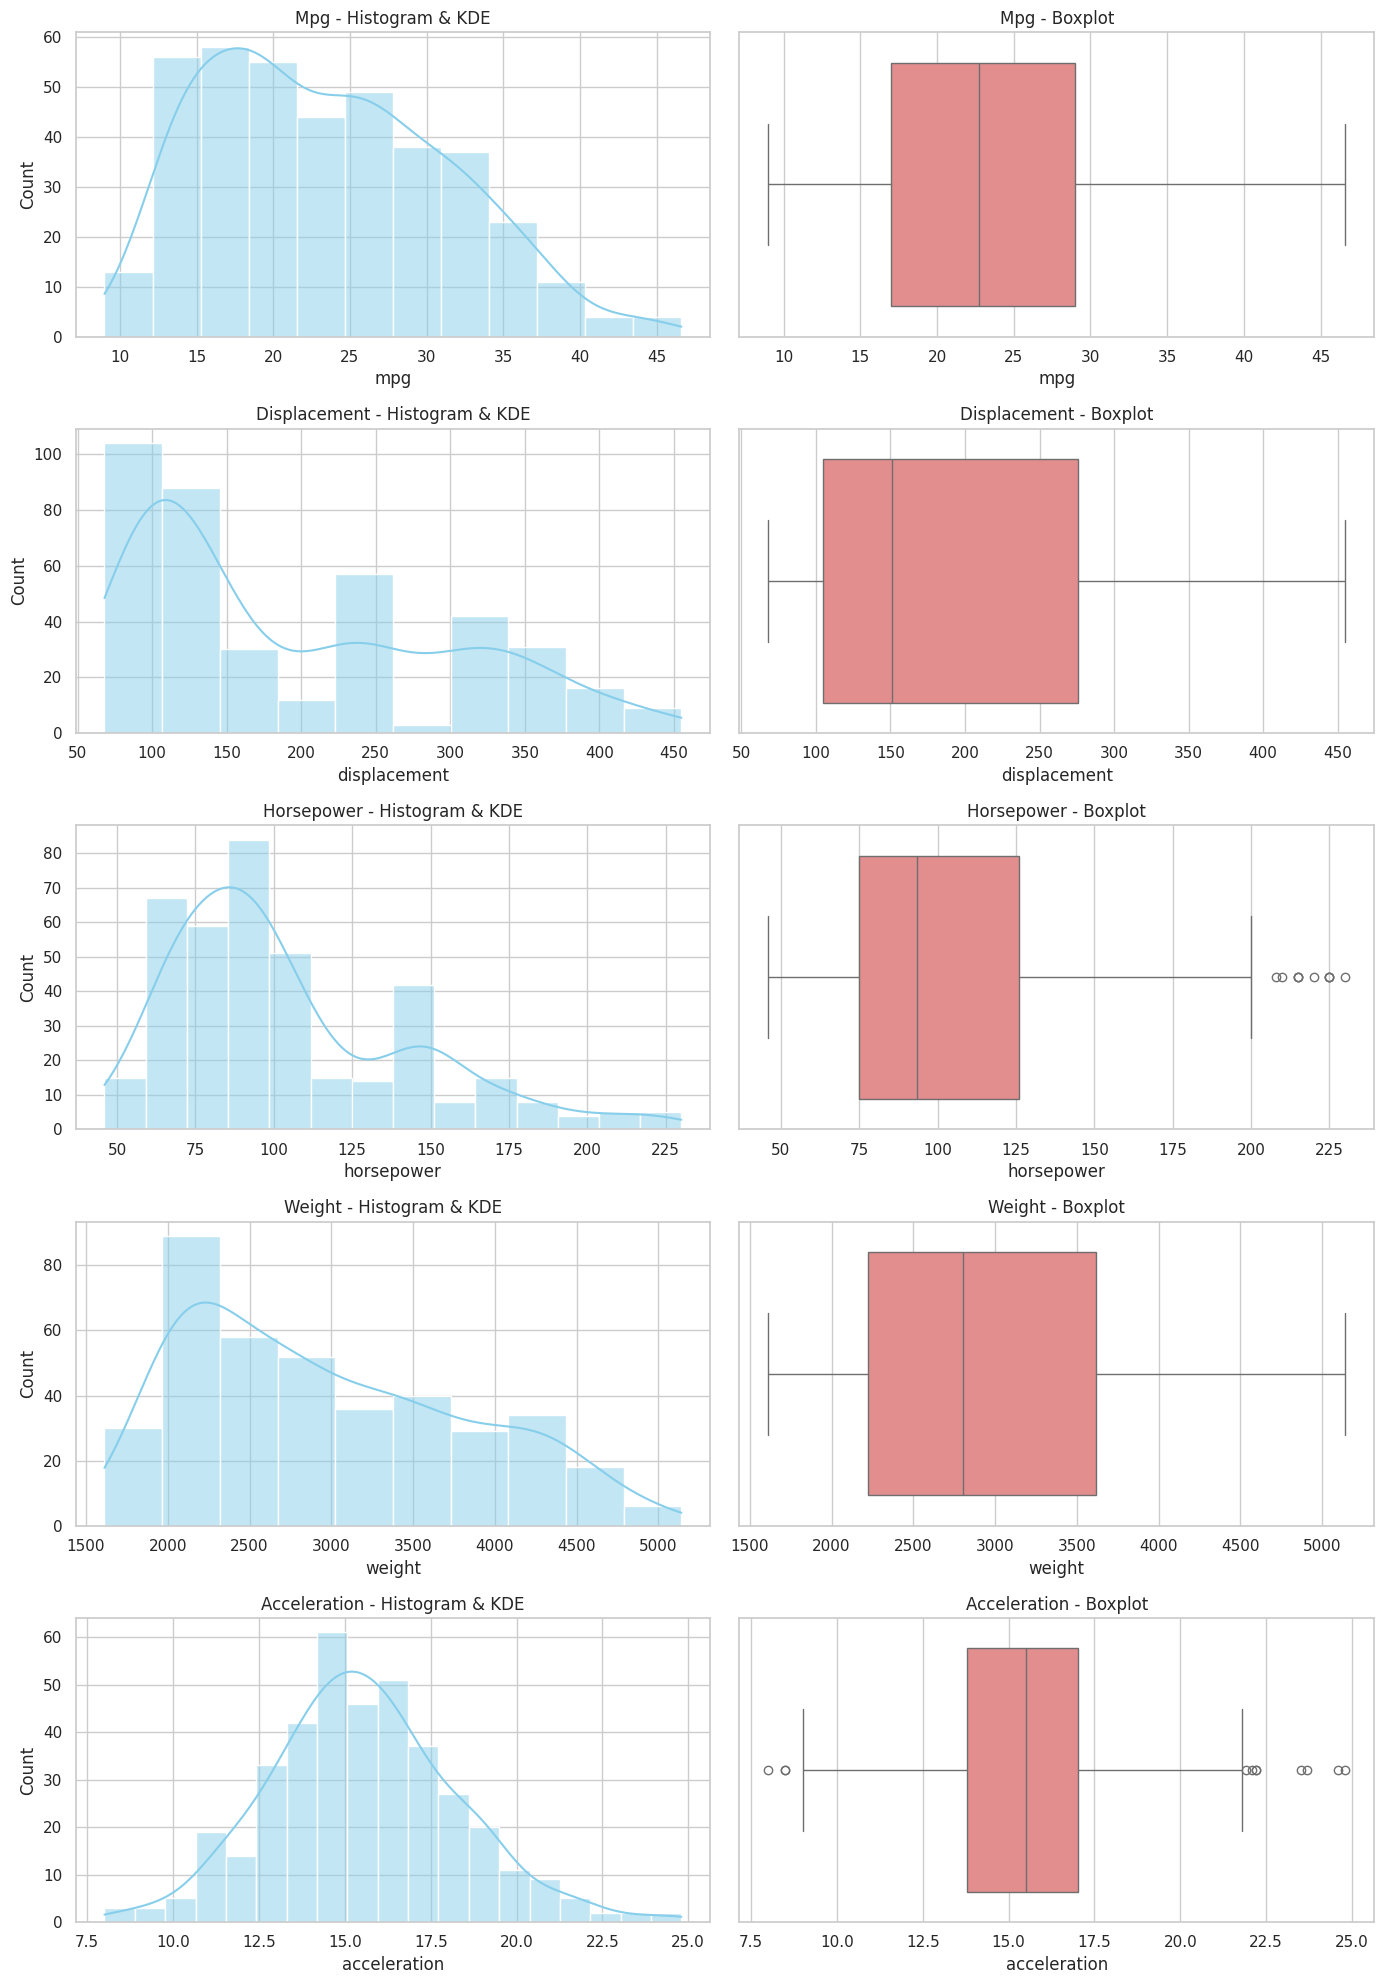

In [15]:
n_cols = len(num_cols)
fig, axes = plt.subplots(n_cols, 2, figsize=(14, 4 * n_cols))

for idx, col in enumerate(num_cols):
    # (a) Histogram + KDE
    sns.histplot(data=df, x=col, kde=True, ax=axes[idx, 0], color='skyblue')
    axes[idx, 0].set_title(f'{col.capitalize()} - Histogram & KDE')

    # (b) Boxplot
    sns.boxplot(data=df, x=col, ax=axes[idx, 1], color='lightcoral')
    axes[idx, 1].set_title(f'{col.capitalize()} - Boxplot')

plt.tight_layout()
plt.show()

In [16]:
def tukey_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = series[(series < lower_bound) | (series > upper_bound)]
    return outliers

for col in num_cols:
    outliers = tukey_outliers(df[col])
    print(f"{col}: found {len(outliers)} outliers. Values: {list(outliers.values)}")

mpg: found 0 outliers. Values: []
displacement: found 0 outliers. Values: []
horsepower: found 10 outliers. Values: [np.float64(220.0), np.float64(215.0), np.float64(225.0), np.float64(225.0), np.float64(215.0), np.float64(210.0), np.float64(208.0), np.float64(215.0), np.float64(225.0), np.float64(230.0)]
weight: found 0 outliers. Values: []
acceleration: found 11 outliers. Values: [np.float64(8.5), np.float64(8.5), np.float64(8.0), np.float64(23.5), np.float64(22.2), np.float64(22.1), np.float64(21.9), np.float64(24.8), np.float64(22.2), np.float64(23.7), np.float64(24.6)]


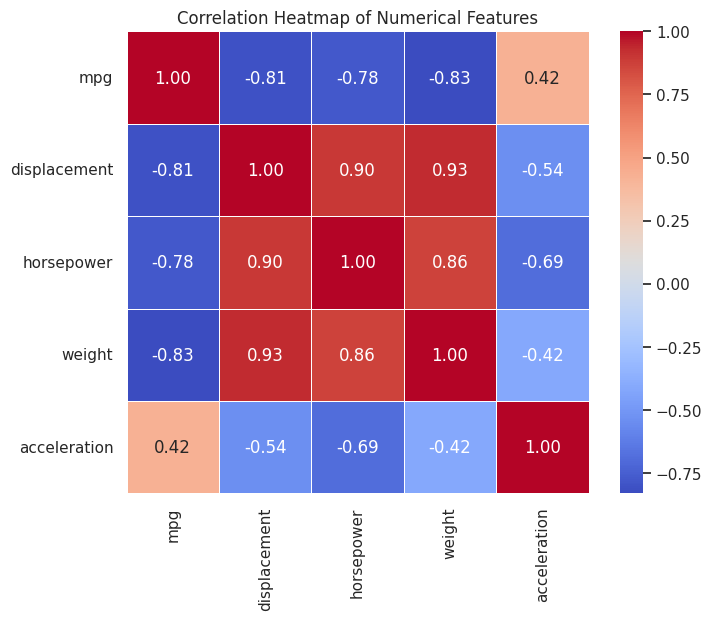

In [17]:
plt.figure(figsize=(8, 6))
corr_matrix = df[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', square=True, linewidths=.5)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

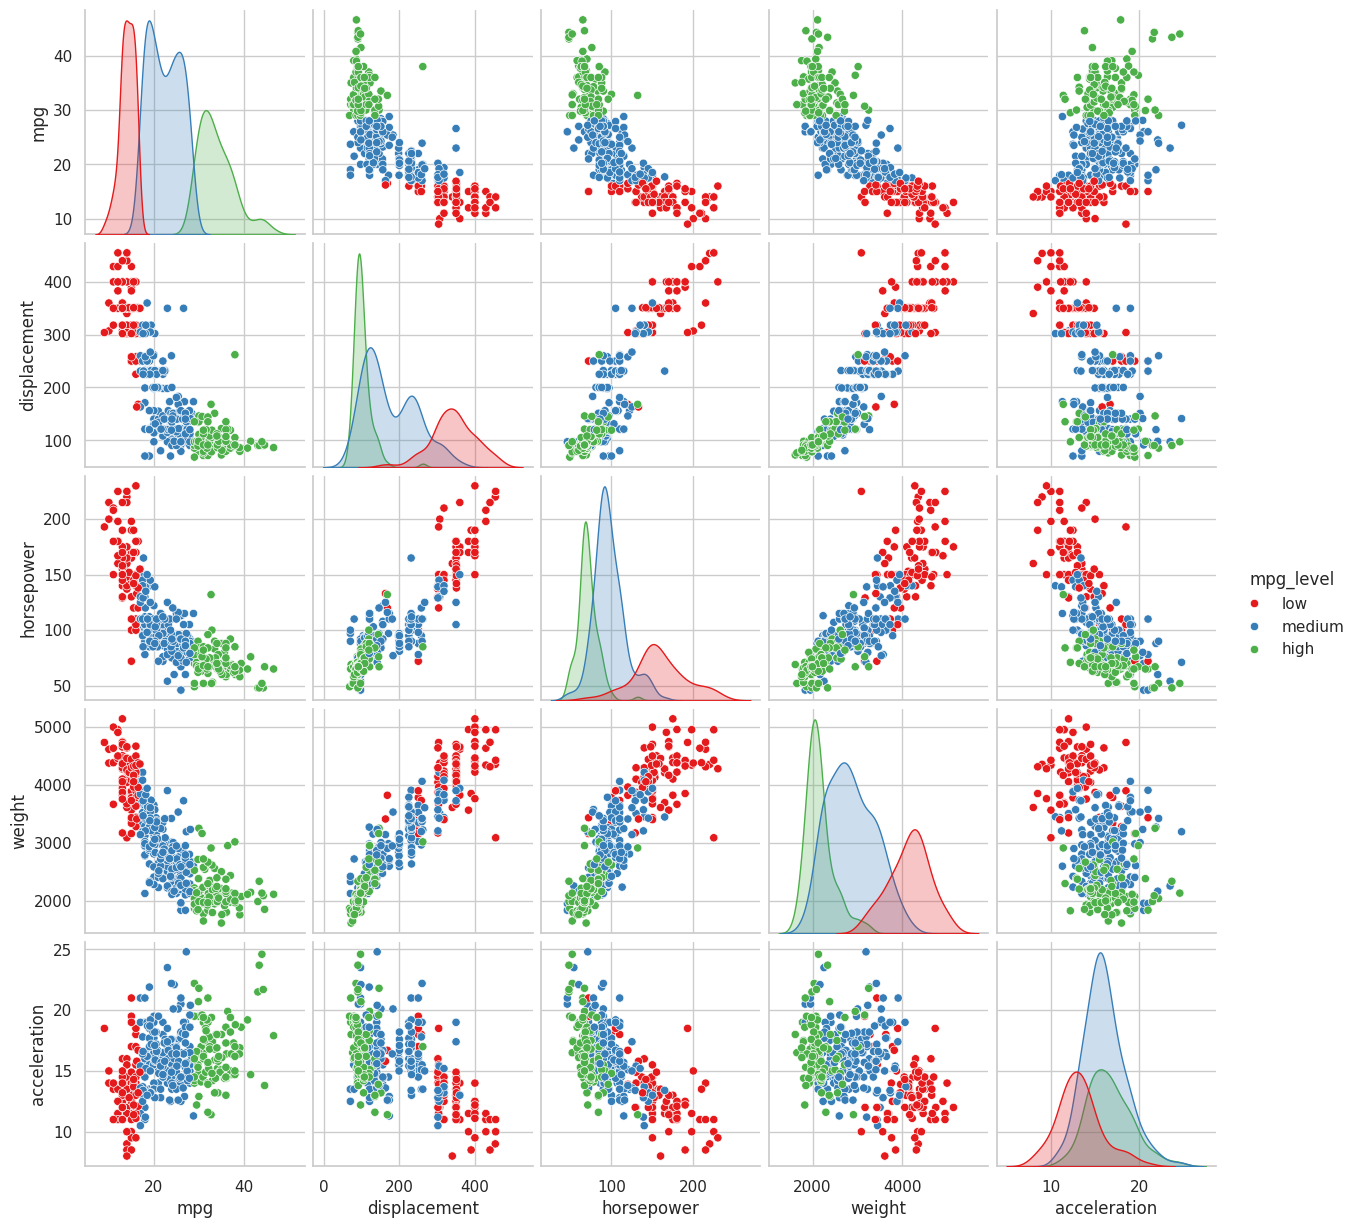

In [18]:
sns.pairplot(df[num_cols + ['mpg_level']], hue='mpg_level', palette='Set1')
plt.show()

**Q5.** Which two numerical features have the strongest negative correlation with mpg?  
**Answer:** `weight` (correlation of -0.83) and `displacement` (correlation of -0.81).

**Q6.** Is the `acceleration` distribution approximately Gaussian? Justify briefly.  
**Answer:** **Yes**, it is approximately Gaussian because the histogram and KDE plot show a highly symmetric, bell-shaped distribution centered around 15.5.

## Task 7 — Numerical vs Categorical

/tmp/ipykernel_1069/1358110408.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(data=df, x='origin', y=col, ax=axes[idx], palette='muted')
/tmp/ipykernel_1069/1358110408.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(data=df, x='origin', y=col, ax=axes[idx], palette='muted')
/tmp/ipykernel_1069/1358110408.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(data=df, x='origin', y=col, ax=axes[idx], palette='muted')
/tmp/ipykernel_1069/1358110408.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and w

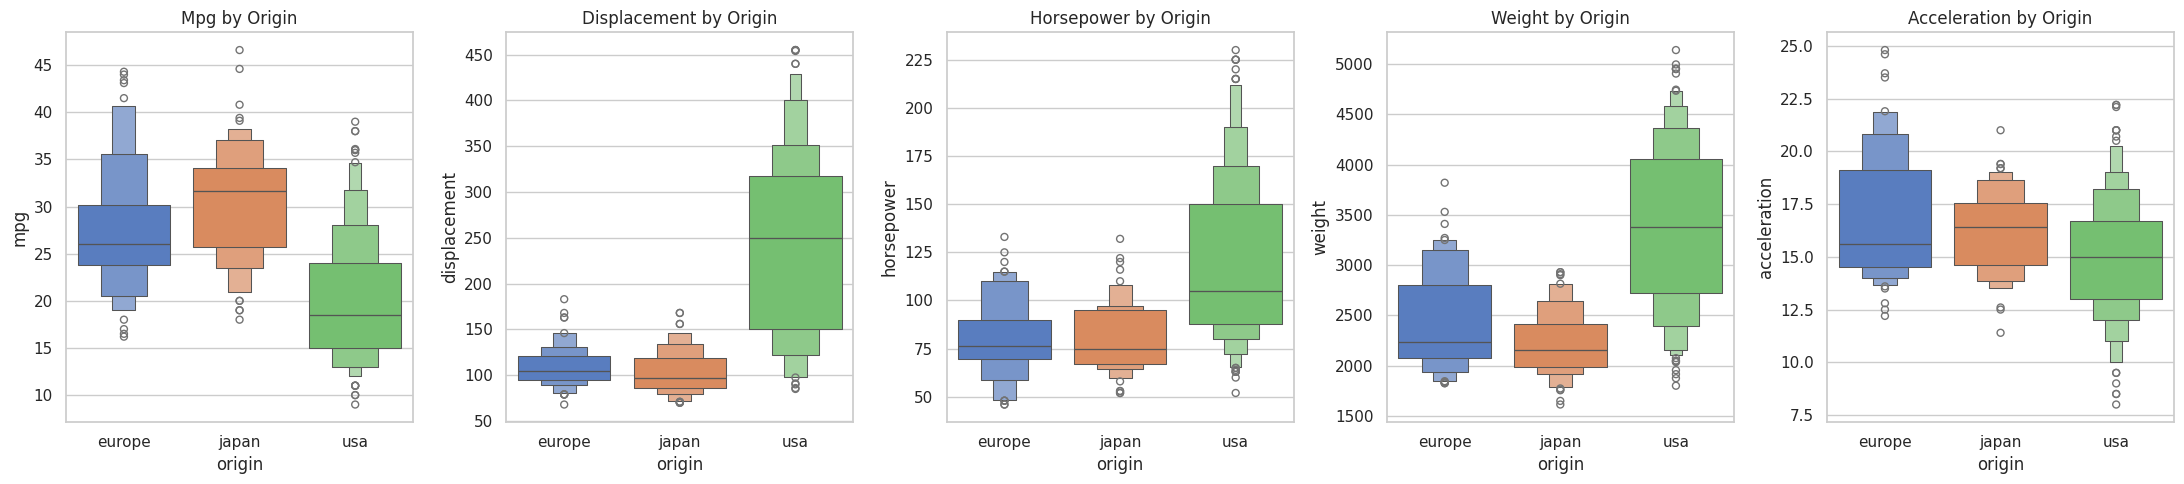

In [19]:
fig, axes = plt.subplots(1, 5, figsize=(22, 5))

for idx, col in enumerate(num_cols):
    sns.boxenplot(data=df, x='origin', y=col, ax=axes[idx], palette='muted')
    axes[idx].set_title(f'{col.capitalize()} by Origin')

plt.tight_layout()
plt.show()

/tmp/ipykernel_1069/1964291354.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='mpg_level', y=col, ax=axes[idx], palette='pastel')
/tmp/ipykernel_1069/1964291354.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='mpg_level', y=col, ax=axes[idx], palette='pastel')
/tmp/ipykernel_1069/1964291354.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='mpg_level', y=col, ax=axes[idx], palette='pastel')
/tmp/ipykernel_1069/1964291354.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is d

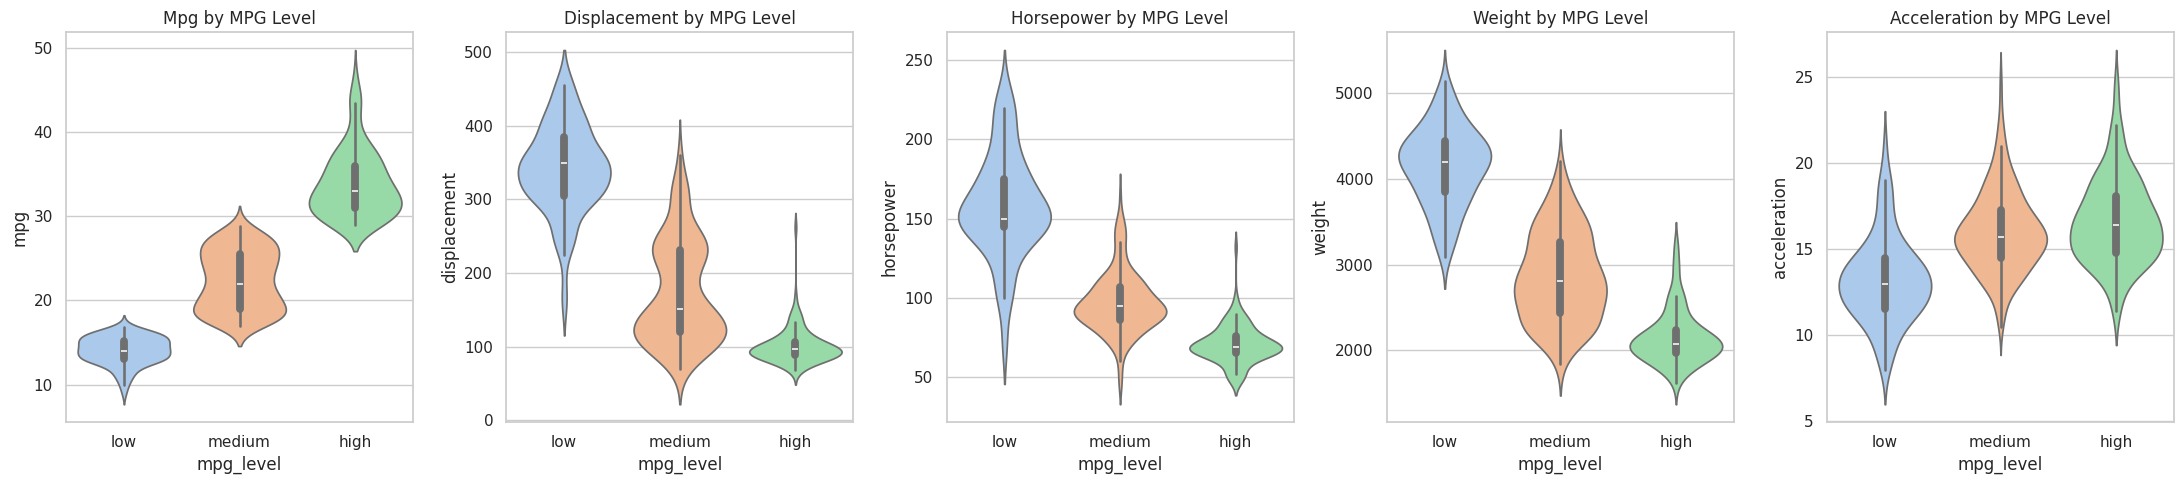

In [20]:
fig, axes = plt.subplots(1, 5, figsize=(22, 5))

for idx, col in enumerate(num_cols):
    sns.violinplot(data=df, x='mpg_level', y=col, ax=axes[idx], palette='pastel')
    axes[idx].set_title(f'{col.capitalize()} by MPG Level')

plt.tight_layout()
plt.show()

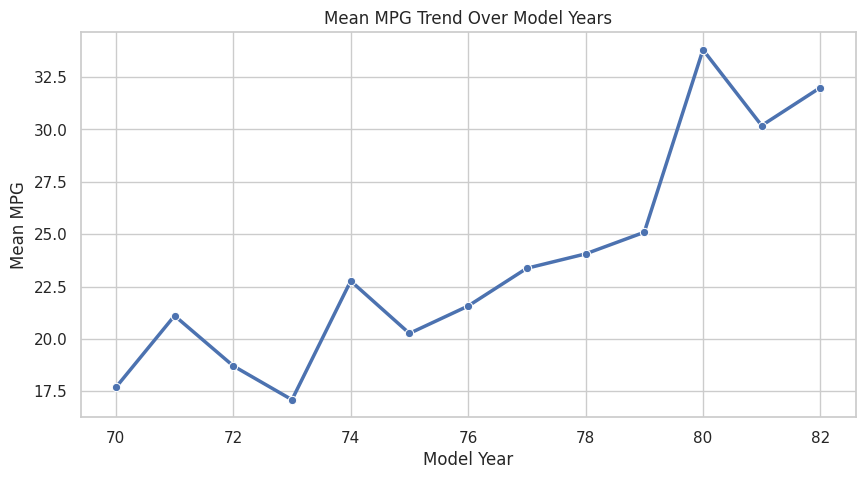

In [21]:
plt.figure(figsize=(10, 5))
mean_mpg_by_year = df.groupby('model_year', observed=False)['mpg'].mean().reset_index()
sns.lineplot(data=mean_mpg_by_year, x='model_year', y='mpg', marker='o', linewidth=2.5)
plt.title('Mean MPG Trend Over Model Years')
plt.xlabel('Model Year')
plt.ylabel('Mean MPG')
plt.show()

**Q7.** On average, which origin produces cars with the lowest mpg?  
**Answer:** **usa** produces cars with the lowest mpg on average.

**Q8.** Describe in one sentence how mpg changes as model_year increases.  
**Answer:** On average, vehicle fuel efficiency (mpg) shows a strong upward trend as model year increases from 1970 to 1982.

## Task 8 — Summary Table
Fill in the table below based on your analysis.

| Feature | Relationship with MPG | Strength |
|---|---|---|
| displacement | Negative | Strong (-0.81) |
| horsepower | Negative | Strong (-0.78) |
| weight | Negative | Strong (-0.83) |
| acceleration | Positive | Moderate (0.42) |
| cylinders | Negative | Strong (fewer cylinders generally have higher MPG) |
| origin | Categorical | USA has lowest MPG; Europe and Japan have significantly higher MPG |
| model_year | Positive | Strong (MPG continuously increases over time) |